# Student Academic Risk Prediction

**Goal:** Predict academic-risk categories from student-related features using supervised machine learning.

**Workflow:** Data inspection → cleaning → EDA → preprocessing → 5-fold cross-validation → test evaluation.

**Dataset note:** The supplied dataset is synthetic and should not be treated as evidence about real students.

## 1. Imports and setup

In [2]:
from pathlib import Path
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier, ExtraTreesClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, ConfusionMatrixDisplay)

warnings.filterwarnings("ignore", category=FutureWarning)
DATA_PATH = next((p for p in [Path("student_academic_risk_dataset.csv"),
                              Path("dataset/student_academic_risk_dataset.csv"),
                              Path("/mnt/data/student_academic_risk_dataset.csv")] if p.exists()),
                 Path("student_academic_risk_dataset.csv"))
RANDOM_STATE = 42

## 2. Load and inspect the data

In [3]:
df = pd.read_csv(DATA_PATH)
print("Dataset shape:", df.shape)
display(df.head())
display(df.isna().sum().sort_values(ascending=False).rename("Missing values").to_frame())
print("Duplicate rows:", df.duplicated().sum())
display(df["Academic_Risk"].value_counts(dropna=False).rename("Count").to_frame())

Dataset shape: (6008, 14)


,Student_ID,Age,Gender,Program,Study_Hours_Per_Week,Attendance_Percent,Previous_Average_Score,Assignment_Score,Internet_Access,Part_Time_Work,Financial_Stress,Commute_Minutes,Missed_Deadlines,Academic_Risk
0,STU00001,18,Male,Education,16.0,100.0,70.3,75.9,Yes,No,Medium,42.4,1,Not_At_Risk
1,STU00002,27,Male,IT,17.4,91.4,52.6,47.3,Yes,No,High,27.6,2,Not_At_Risk
2,STU00003,26,Female,Engineering,11.4,80.2,81.8,66.3,Yes,Yes,Low,41.7,1,Not_At_Risk
3,STU00004,23,Male,IT,4.8,80.5,70.7,36.0,Yes,No,Low,49.2,3,At_Risk
4,STU00005,23,Female,IT,NaN,86.7,82.1,85.1,Yes,No,Low,23.8,1,Not_At_Risk


,Missing values
Study_Hours_Per_Week,81
Previous_Average_Score,59
Financial_Stress,54
Internet_Access,52
Age,0
Student_ID,0
Attendance_Percent,0
Program,0
Gender,0
Assignment_Score,0


Duplicate rows: 4


,Count
Academic_Risk,
Not_At_Risk,3290
At_Risk,2718


## 3. Clean the data

In [4]:
df = df.drop_duplicates().dropna(subset=["Academic_Risk"]).copy()
print("Shape after cleaning:", df.shape)

Shape after cleaning: (6004, 14)


## 4. Exploratory data analysis

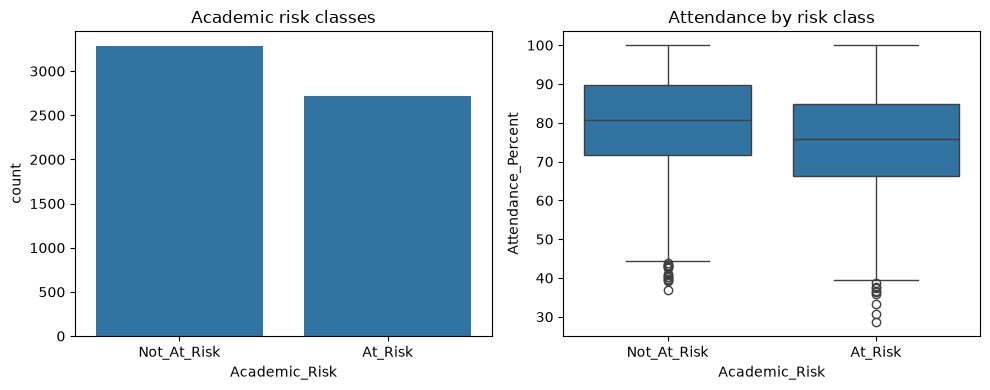

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(10, 4))
sns.countplot(data=df, x="Academic_Risk", ax=ax[0])
ax[0].set_title("Academic risk classes")
sns.boxplot(data=df, x="Academic_Risk", y="Attendance_Percent", ax=ax[1])
ax[1].set_title("Attendance by risk class")
plt.tight_layout()
plt.show()

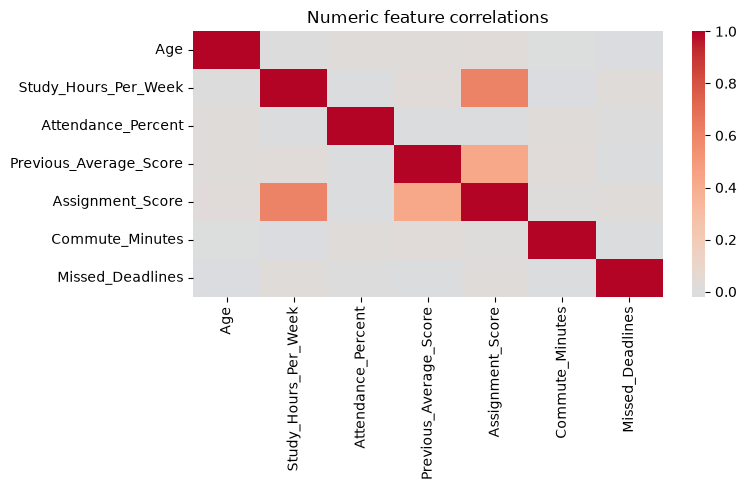

In [6]:
numeric_df = df.select_dtypes(include=np.number)
plt.figure(figsize=(8, 5))
sns.heatmap(numeric_df.corr(), cmap="coolwarm", center=0)
plt.title("Numeric feature correlations")
plt.tight_layout()
plt.show()

## 5. Prepare features and split the data

In [7]:
TARGET = "Academic_Risk"
X = df.drop(columns=["Student_ID", TARGET], errors="ignore")
y = df[TARGET].astype(str)

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE
)
numeric_features = X_train.select_dtypes(include=np.number).columns.tolist()
categorical_features = X_train.select_dtypes(exclude=np.number).columns.tolist()
print(f"Training rows: {len(X_train)} | Test rows: {len(X_test)}")

Training rows: 4803 | Test rows: 1201


## 6. Preprocessing and models

In [8]:
def make_preprocessor():
    numeric = Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler())])
    categorical = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                            ("onehot", OneHotEncoder(handle_unknown="ignore"))])
    return ColumnTransformer([("num", numeric, numeric_features),
                              ("cat", categorical, categorical_features)])

In [9]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1500, class_weight="balanced",
                                               random_state=RANDOM_STATE),
    "Decision Tree": DecisionTreeClassifier(max_depth=8, min_samples_leaf=10,
                                            class_weight="balanced", random_state=RANDOM_STATE),
    "Random Forest": RandomForestClassifier(n_estimators=200, min_samples_leaf=3,
                                             class_weight="balanced_subsample",
                                             n_jobs=-1, random_state=RANDOM_STATE),
    "Extra Trees": ExtraTreesClassifier(n_estimators=200, min_samples_leaf=2,
                                         class_weight="balanced", n_jobs=-1,
                                         random_state=RANDOM_STATE)
}

## 7. Five-fold cross-validation

In [10]:
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
scoring = {"accuracy": "accuracy", "precision": "precision_macro",
           "recall": "recall_macro", "f1": "f1_macro"}
results = []

for name, model in models.items():
    pipe = Pipeline([("preprocess", make_preprocessor()), ("model", model)])
    scores = cross_validate(pipe, X_train, y_train, cv=cv, scoring=scoring, n_jobs=1)
    results.append({"Model": name, **{
        f"{metric}_{stat}": getattr(scores[f"test_{metric}"], stat)()
        for metric in scoring for stat in ("mean", "std")
    }})
cv_results = pd.DataFrame(results).sort_values("f1_mean", ascending=False).reset_index(drop=True)
display(cv_results.round(3))

,Model,accuracy_mean,accuracy_std,precision_mean,precision_std,recall_mean,recall_std,f1_mean,f1_std
0,Logistic Regression,0.661,0.006,0.660,0.007,0.661,0.007,0.659,0.007
1,Random Forest,0.650,0.004,0.646,0.005,0.645,0.005,0.645,0.005
2,Extra Trees,0.638,0.011,0.634,0.011,0.633,0.011,0.633,0.011
3,Decision Tree,0.595,0.008,0.591,0.009,0.591,0.010,0.590,0.010


## 8. Best model: test-set evaluation

In [11]:
best_name = cv_results.loc[0, "Model"]
best_model = Pipeline([("preprocess", make_preprocessor()), ("model", models[best_name])])
best_model.fit(X_train, y_train)
y_pred = best_model.predict(X_test)

print("Selected model:", best_name)
print(f"Accuracy:          {accuracy_score(y_test, y_pred):.3f}")
print(f"Macro precision:   {precision_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print(f"Macro recall:      {recall_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print(f"Macro F1-score:    {f1_score(y_test, y_pred, average='macro', zero_division=0):.3f}")
print(classification_report(y_test, y_pred, zero_division=0))

Selected model: Logistic Regression
Accuracy:          0.689
Macro precision:   0.687
Macro recall:      0.688
Macro F1-score:    0.687
              precision    recall  f1-score   support

     At_Risk       0.65      0.67      0.66       544
 Not_At_Risk       0.72      0.70      0.71       657

    accuracy                           0.69      1201
   macro avg       0.69      0.69      0.69      1201
weighted avg       0.69      0.69      0.69      1201



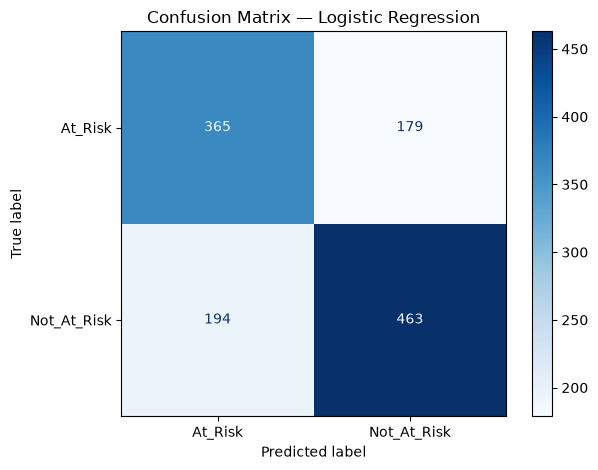

In [12]:
ConfusionMatrixDisplay.from_estimator(best_model, X_test, y_test, cmap="Blues", values_format="d")
plt.title(f"Confusion Matrix — {best_name}")
plt.tight_layout()
plt.show()

## 9. Compare models and save results

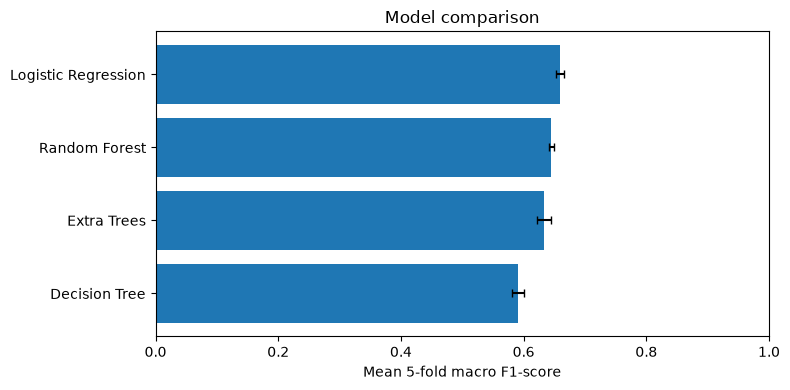

Saved cross_validation_model_comparison.csv


In [13]:
plt.figure(figsize=(8, 4))
plot_df = cv_results.sort_values("f1_mean")
plt.barh(plot_df["Model"], plot_df["f1_mean"], xerr=plot_df["f1_std"], capsize=3)
plt.xlabel("Mean 5-fold macro F1-score")
plt.xlim(0, 1)
plt.title("Model comparison")
plt.tight_layout()
plt.show()

cv_results.to_csv("cross_validation_model_comparison.csv", index=False)
print("Saved cross_validation_model_comparison.csv")

In [19]:
import joblib

# Save the best model pipeline to disk
joblib.dump(best_model, "student_academicrisk.keras")
print("Saved best model successfully to student_academicrisk.keras")

Saved best model successfully to student_academicrisk.keras


## 10. Conclusion and limitations

- **Accuracy:** fraction of predictions that are correct.
- **Precision:** how often predicted class labels are correct.
- **Recall:** how many actual cases are identified.
- **Macro F1:** balances precision and recall equally across classes.
- Cross-validation compares models using training data; the held-out test set provides the final evaluation.
- High training performance does not guarantee good predictions on unseen data.

**Important:** This is a synthetic educational dataset. Results do not establish real-world student risk. Real deployment would require ethically collected data, privacy and fairness checks, and independent validation.